# Bayesian optimization of VCSEL oxide-aperture geometry for polarization-switching photonic Ising machines
**Status: a literature-anchored simulation study.** The constants of the model are *not measured*: they are constrained only by the qualitative outcomes
that the fabricated-device papers report (Yuan et al. 2025), by approximate Bayesian computation. Every number below is a **model prediction conditional on those constraints**;
nothing is validated on a device of this project. The notebook reads the cached results of `scripts/run_all.sh` and runs a few live calls that take seconds.

Pipeline: mask parameters (L, arm ratio, w, corner rounding, rotation) -> exact drawn cross -> anisotropic lateral oxidation (eroded aperture) -> second-rank boundary tensors
-> dichroism / birefringence = native + coupling x tensor -> spin-flip model (fixed points + stability) -> yield (checklist) -> Bayesian optimisation and batch (portfolio) design.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from vcsel_bo import geometry as G, physics as P, objective as O, optimization as opt, sfm, literature as L, problem as PR
np.set_printoptions(precision=3, suppress=True)
RES = ROOT / 'results'
def J(name): return json.loads((RES / name).read_text())

## 1. Geometry: drawn mesa, oxide aperture, second-rank descriptors

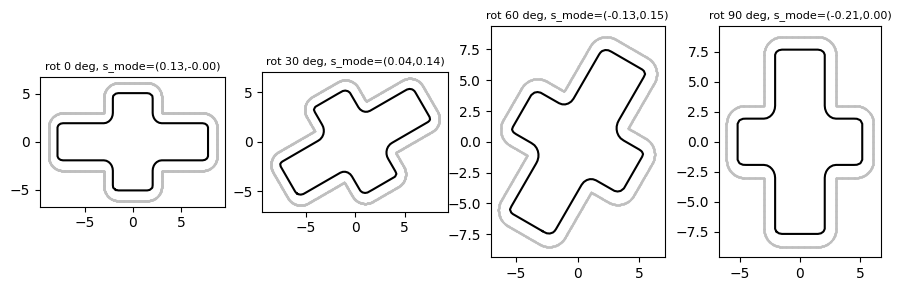

C4 symmetric cross, isotropic oxidation: |s_mode| = 5.435744230399981e-16 (exactly 0 by symmetry)


In [2]:
fig, axs = plt.subplots(1, 4, figsize=(11, 3))
proc = G.Process()   # placeholder oxidation depth / anisotropy
for ax, th in zip(axs, (0, 30, 60, 90)):
    d = G.MaskDesign(17.5, 0.7, 6.0, 0.5, th)
    ap = G.build_aperture(d, proc)
    m = G.mesa_boundary(d); ax.plot(m[:, 0], m[:, 1], '.', c='0.75', ms=0.5)
    for lp in ap.loops: ax.plot(lp[:, 0], lp[:, 1], 'k')
    ds = G.descriptors(ap)
    ax.set_aspect('equal'); ax.set_title(f'rot {th} deg, s_mode=({ds.s_mode[0]:.2f},{ds.s_mode[1]:.2f})', fontsize=8)
plt.show()
sym = G.descriptors(G.build_aperture(G.MaskDesign(17.5, 1.0, 6.0, 0.5, 0.0), G.Process(1.0, 1.0)))
print('C4 symmetric cross, isotropic oxidation: |s_mode| =', np.linalg.norm(sym.s_mode), '(exactly 0 by symmetry)')

## 2. Spin-flip model: stable branches, and validation against time-domain integration

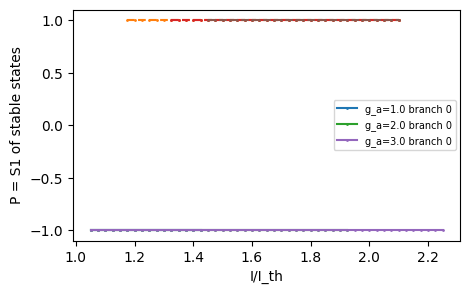

36 sweep points; columns: ['gamma_a', 'mu', 'n_stable_fixed_points', 'P_stable', 'P_time_domain', 'agree']


In [3]:
Cst = sfm.SFMConstants()
mus = np.linspace(1.05, 2.25, 49)
fig, ax = plt.subplots(figsize=(5, 3))
for ga in (1.0, 2.0, 3.0):
    for which, ls in ((0, '-'), (1, '--')):
        m11 = np.full(mus.shape, ga + 20j, dtype=complex); m12 = np.zeros(mus.shape, complex)
        u0 = sfm.linear_mode_guess(mus, m11, m12, Cst, which)
        u, ok = sfm.newton_fixed_point(u0, mus, m11, m12, Cst)
        lam = sfm.stability(u, mus, m11, m12, Cst)
        ax.plot(mus[lam < -1e-3], sfm.stokes(u)['P'][lam < -1e-3], ls, marker='.', ms=2, label=f'g_a={ga} branch {which}' if which == 0 else None)
ax.set_xlabel('I/I_th'); ax.set_ylabel('P = S1 of stable states'); ax.legend(fontsize=7); plt.show()
import csv
rows = list(csv.DictReader(open(RES / 'sfm_validation.csv')))
print(len(rows), 'sweep points; columns:', list(rows[0].keys()))

## 3. Anchoring the model to the published devices
The papers report outcomes per design, not numbers. Each outcome is a yes/no test on a simulated device population; worlds (constants of the model, including signs) are drawn from a broad prior and kept
only if they pass all enforced tests (rejection ABC). Details and the sources of each anchor: `docs/LITERATURE_ANCHORS.md`, supplement Sec. 3.

181 of 8000 prior draws accepted (2.3 %)
d0   median     1.95   5-95 %: [1.06, 7.83]   share > 0: 1.00
b0   median    26.95   5-95 %: [5.92, 82.44]   share > 0: 0.95
k_d  median   -20.52   5-95 %: [-51.67, -9.23]   share > 0: 0.00
k_b  median   -28.28   5-95 %: [-167.94, 36.62]   share > 0: 0.25
share of prior draws passing each anchor alone: {'A1': 0.75, 'A2': 0.75, 'A3': 0.29, 'A5': 0.1, 'A4': 0.07, 'A6': 0.13}


reference world passes all enforced anchors: True


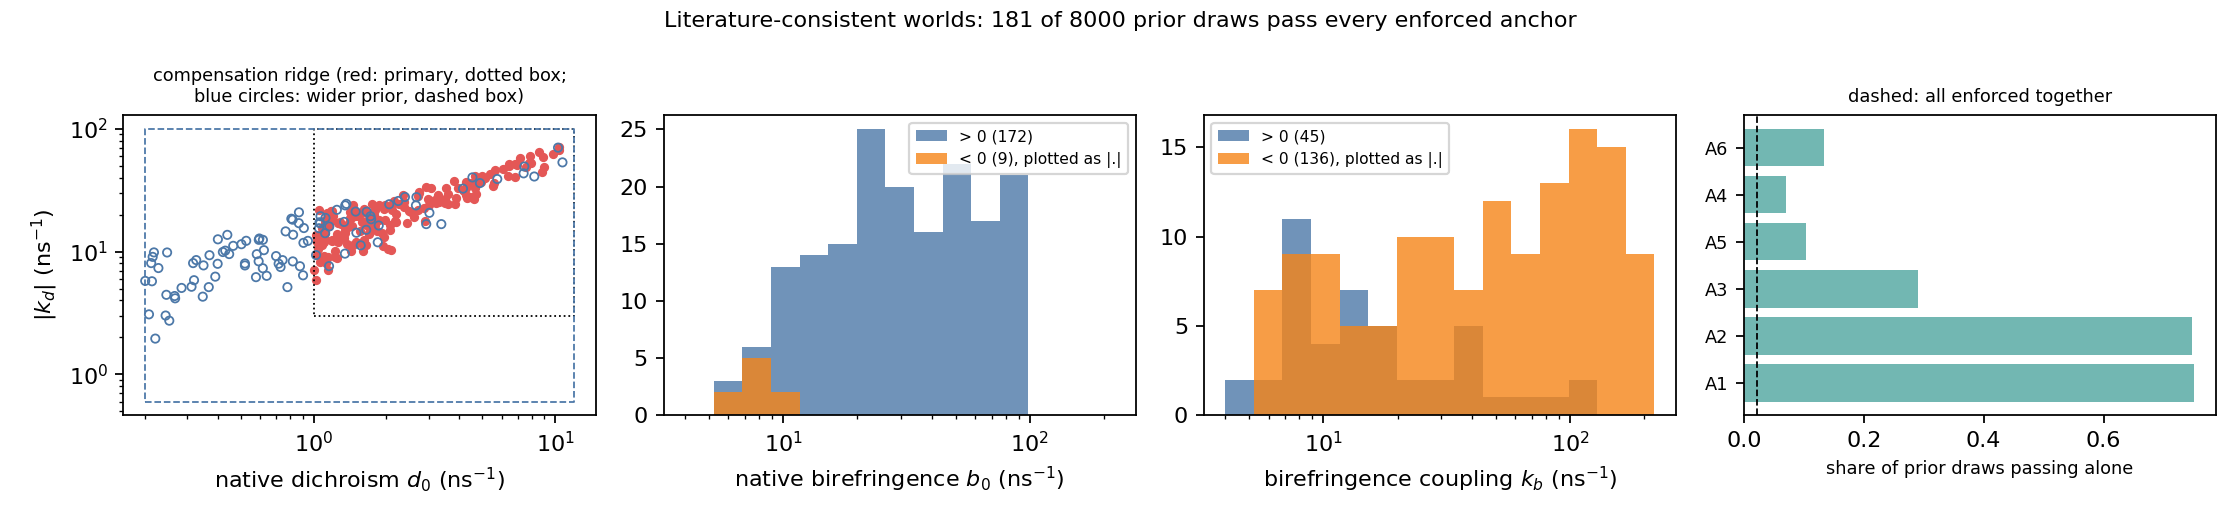

In [4]:
A = J('anchored_worlds.json')
print(f"{A['n_accepted']} of {A['n_draws']} prior draws accepted ({100*A['acceptance']:.1f} %)")
for k, v in A['posterior'].items():
    print(f"{k:4s} median {v['median']:8.2f}   5-95 %: [{v['q05']:.2f}, {v['q95']:.2f}]   share > 0: {v['frac_positive']:.2f}")
print('share of prior draws passing each anchor alone:', {k.split('_')[0]: round(v, 2) for k, v in A['marginal']['per_anchor'].items()})
pop = P.Population.make(24, 777)
rep = L.anchor_report(P.World(), pop)
print('reference world passes all enforced anchors:', rep['ok_enforced'])
display(Image(str(ROOT / 'figures' / 'anchored_worlds.png')))

Not reproduced by the model (reported, not tuned away): switching of the 30 degree cruciform and a symmetric cross that switches more often than a circle; see supplement Sec. 3.

## 4. Predicted yield of published and own designs (mean over literature-consistent worlds)

181 worlds
circle     mean yield 0.00  [10%,90%] [0.00,0.00]  P(yield>=0.5) 0.00  mean P(switch) 0.00
square     mean yield 0.00  [10%,90%] [0.00,0.00]  P(yield>=0.5) 0.00  mean P(switch) 0.01
sym_cross  mean yield 0.00  [10%,90%] [0.00,0.01]  P(yield>=0.5) 0.00  mean P(switch) 0.02
x07_0      mean yield 0.00  [10%,90%] [0.00,0.00]  P(yield>=0.5) 0.00  mean P(switch) 0.00
x07_30     mean yield 0.02  [10%,90%] [0.00,0.00]  P(yield>=0.5) 0.02  mean P(switch) 0.07
x07_60     mean yield 0.30  [10%,90%] [0.00,0.88]  P(yield>=0.5) 0.25  mean P(switch) 0.55
x07_90     mean yield 0.43  [10%,90%] [0.03,0.93]  P(yield>=0.5) 0.42  mean P(switch) 0.58
x06_0      mean yield 0.00  [10%,90%] [0.00,0.00]  P(yield>=0.5) 0.00  mean P(switch) 0.00
x06_90     mean yield 0.06  [10%,90%] [0.00,0.14]  P(yield>=0.5) 0.05  mean P(switch) 0.10
mask_A0    mean yield 0.00  [10%,90%] [0.00,0.00]  P(yield>=0.5) 0.00  mean P(switch) 0.00
mask_A30   mean yield 0.03  [10%,90%] [0.00,0.00]  P(yield>=0.5) 0.03  mean P(s

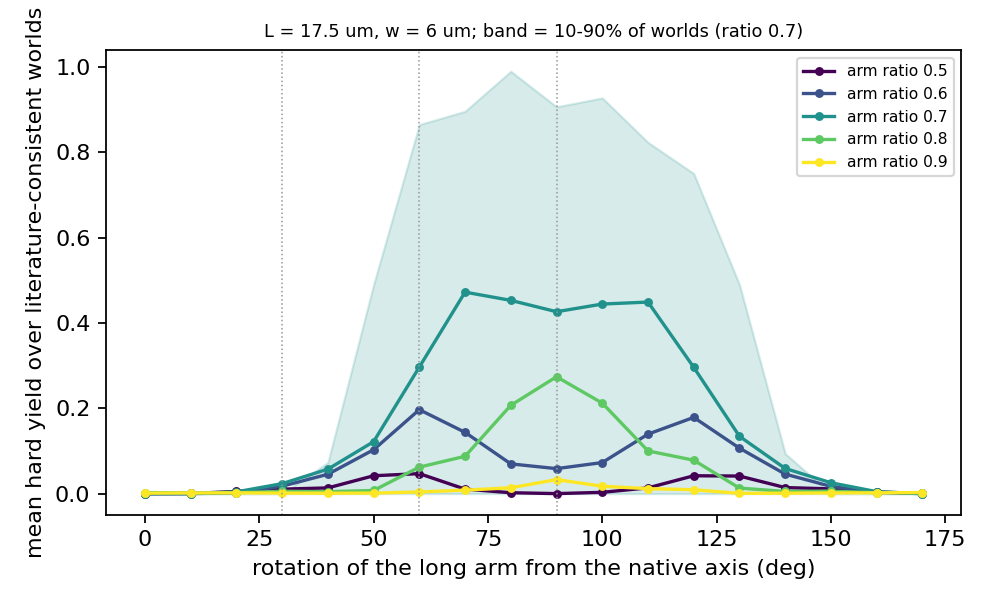

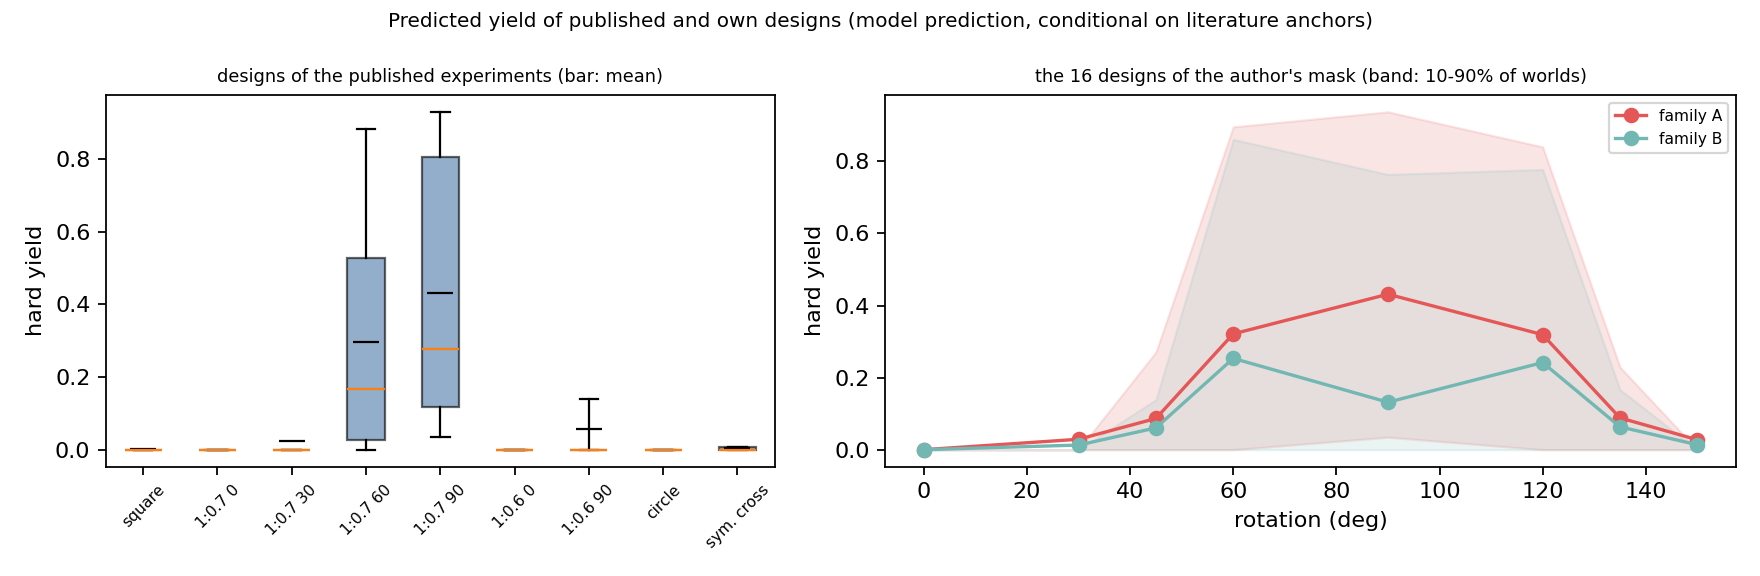

In [5]:
D = J('literature_designs.json')
print(f"{D['n_worlds']} worlds")
for k, s in D['designs'].items():
    print(f"{k:10s} mean yield {s['mean_yield']:.2f}  [10%,90%] [{s['q10']:.2f},{s['q90']:.2f}]  P(yield>=0.5) {s['p_yield_ge_half']:.2f}  mean P(switch) {s['mean_p_switch']:.2f}")
print('best of the seven designs of APL 126, share of worlds:', {k: round(v, 2) for k, v in D['apl126_seven_top_frequency'].items()},
      ' no working design among the seven:', round(D['apl126_seven_no_working_design_fraction'], 2))
display(Image(str(ROOT / 'figures' / 'rotation_scan.png'))); display(Image(str(ROOT / 'figures' / 'designs.png')))

In [6]:
W = J('window_dependence.json')
print('1:0.7 cross, mean yield at rotations', W['thetas'], 'for different switching-current windows')
for k, v in W['windows'].items():
    print(f"{k:20s}", np.round(v['mean_yield'], 2), ' best', v['best_theta'], ' P(60>90)', round(v['share_worlds_60_beats_90'], 2), ' P(90>60)', round(v['share_worlds_90_beats_60'], 2))

1:0.7 cross, mean yield at rotations [40.0, 50.0, 60.0, 70.0, 80.0, 90.0] for different switching-current windows
default 1.25-1.95    [0.05 0.12 0.27 0.43 0.4  0.39]  best 70.0  P(60>90) 0.31  P(90>60) 0.63
low bias 1.15-1.60   [0.05 0.11 0.27 0.39 0.27 0.23]  best 70.0  P(60>90) 0.53  P(90>60) 0.43
wide 1.15-2.05       [0.07 0.16 0.36 0.54 0.48 0.46]  best 70.0  P(60>90) 0.35  P(90>60) 0.6
mid 1.50-1.70        [0.01 0.04 0.06 0.12 0.13 0.12]  best 80.0  P(60>90) 0.23  P(90>60) 0.62


## 5. Optimiser benchmark (cached; `scripts/run_benchmark.py`)

p1 random  held-out yield 0.812  [0.736, 0.880]  n=20
p1 sobol   held-out yield 0.866  [0.798, 0.924]  n=20
p1 de      held-out yield 0.894  [0.842, 0.939]  n=20
p1 bo_ei   held-out yield 0.957  [0.923, 0.983]  n=20
p1 bo_ucb  held-out yield 0.858  [0.740, 0.958]  n=20
p2 random  held-out yield 0.331  [0.288, 0.375]  n=40
p2 sobol   held-out yield 0.347  [0.299, 0.390]  n=40
p2 de      held-out yield 0.384  [0.343, 0.425]  n=40
p2 bo_ei   held-out yield 0.431  [0.383, 0.473]  n=40
p2 bo_ucb  held-out yield 0.431  [0.384, 0.476]  n=40
p3 random  held-out yield 0.390  [0.359, 0.422]  n=8
p3 sobol   held-out yield 0.422  [0.380, 0.464]  n=8
p3 de      held-out yield 0.367  [0.322, 0.414]  n=8
p3 bo_ei   held-out yield 0.408  [0.364, 0.454]  n=8
p3 bo_ucb  held-out yield 0.402  [0.382, 0.427]  n=8

p1 bo_ei - random   mean diff +0.145  Wilcoxon p 0.001  pairs 20
p1 bo_ei - sobol    mean diff +0.090  Wilcoxon p 0.001  pairs 20
p1 bo_ei - de       mean diff +0.063  Wilcoxon p 0.008  pairs 20

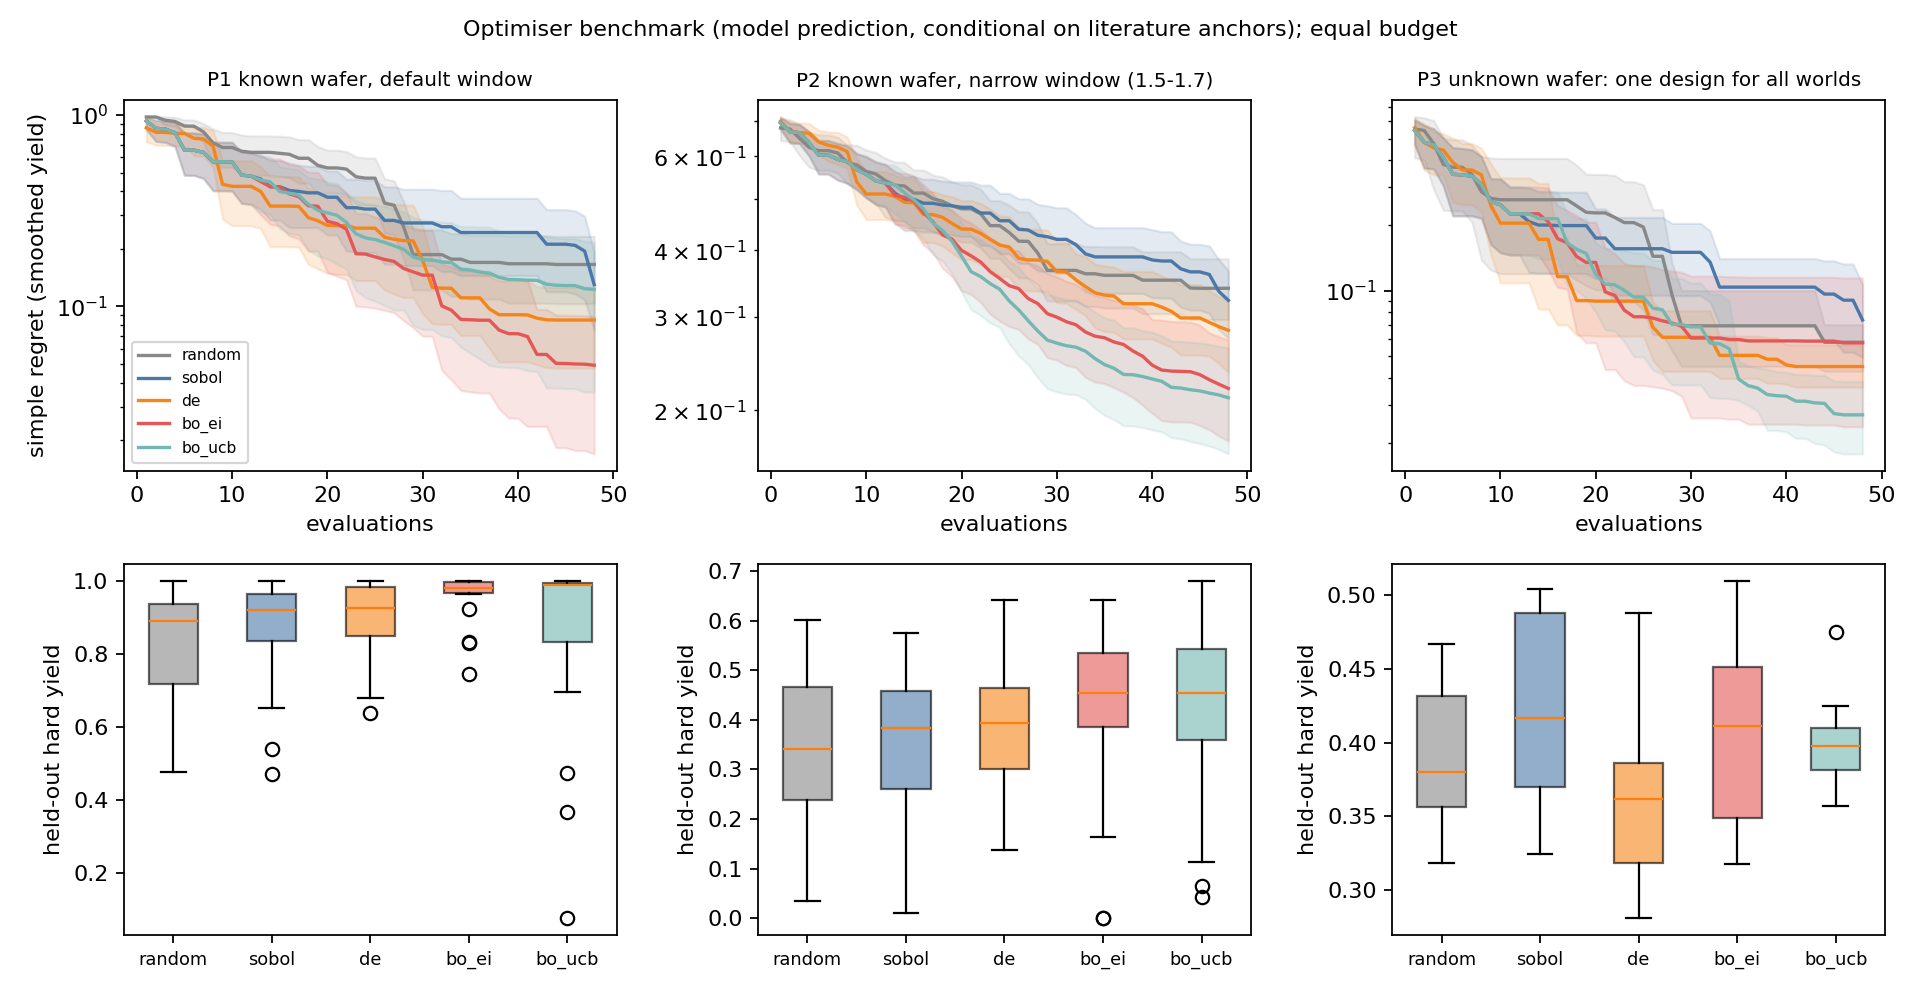

In [7]:
S = J('benchmark_stats.json')
for r in S:
    if 'method' in r: print(f"{r['problem']} {r['method']:7s} held-out yield {r['mean_held_out']:.3f}  [{r['ci_lo']:.3f}, {r['ci_hi']:.3f}]  n={r['n']}")
print()
for r in S:
    if 'test' in r and r['test'] in ('bo_ei - random','bo_ei - sobol','bo_ei - de','bo_ucb - random','bo_ucb - sobol','bo_ucb - de'):
        print(f"{r['problem']} {r['test']:16s} mean diff {r['mean_diff']:+.3f}  Wilcoxon p {r['wilcoxon_p']:.3f}  pairs {r['n_pairs']}")
display(Image(str(ROOT / 'figures' / 'benchmark.png')))

## 6. Fabrication batch (portfolio) and its checks

{'greedy_portfolio': (0.857, 0.938), 'greedy_first8': (0.852, 0.938), 'apl126_seven_designs': (0.573, 0.594), 'author_mask_16_designs': (0.685, 0.719), 'rotation_family_8': (0.709, 0.781)}
designs of the portfolio on a wall of the search box: 8 of 16
fresh device population: {'portfolio': 0.858, 'interior_portfolio': 0.81, 'author_mask': 0.671, 'apl126_seven': 0.577}
expected best-of-batch yield, 32 test worlds vs 117 further accepted worlds (never used for selection): {'portfolio_16': (0.86, 0.74), 'portfolio_first8': (0.85, 0.74), 'mask_16': (0.68, 0.61), 'seven_published': (0.57, 0.56), 'rotation_family_8': (0.71, 0.6), 'mask_plus_3_pool': (0.85, 0.72), 'mask_plus_3_interior': (0.83, 0.72)}
id,origin,L_um,arm_ratio,arm_width_um,corner_rho,corner_radius_um,rotation_deg,E_yield_train,E_yield_test,P_yield_ge_half_test
0,bo1,19.708,0.500,3.500,1.000,1.750,84.61,0.581,0.689,0.750
1,bo0,12.961,0.844,8.000,0.213,0.851,88.38,0.410,0.410,0.438
2,sobol,18.594,0.776,6.343,0.518,1.642,79.54,0.2

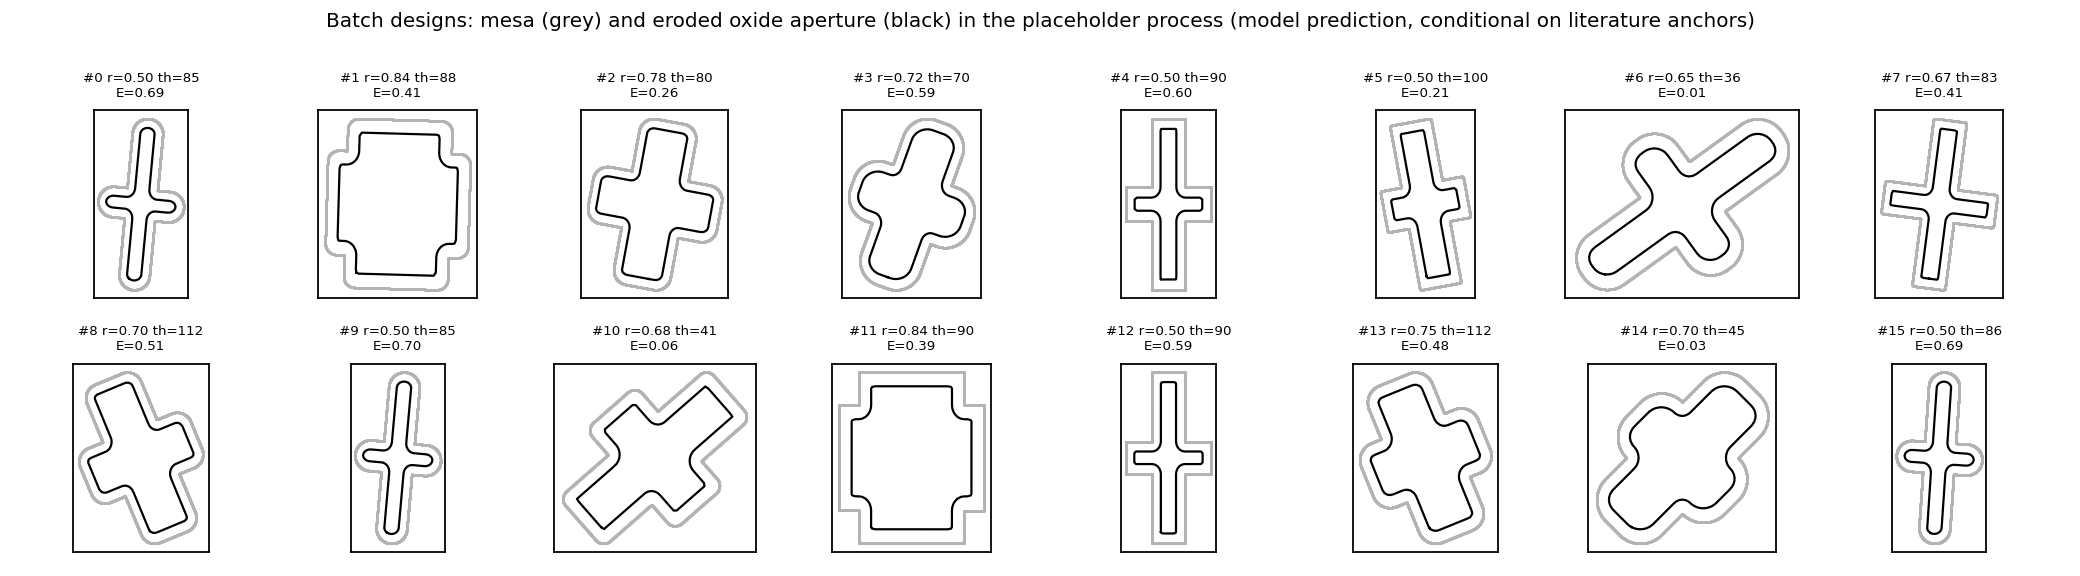

In [8]:
B = J('batch_summary.json')['test']
print({k: (round(v['E_best_yield'], 3), round(v['P_some_design_ge_half'], 3)) for k, v in B.items() if isinstance(v, dict) and 'E_best_yield' in v})
R = J('robustness_extras.json')
print('designs of the portfolio on a wall of the search box:', sum(1 for d in R['portfolio_info'] if d['on_wall']), 'of', R['q'])
print('fresh device population:', {k: round(v['E_best_yield'], 3) for k, v in R['test_fresh_devices'].items() if isinstance(v, dict) and 'E_best_yield' in v})
O2 = J('other_worlds_check.json')
print('expected best-of-batch yield, 32 test worlds vs', O2['n_other_worlds'], 'further accepted worlds (never used for selection):',
      {k: (round(v['test'], 2), round(v['other'], 2)) for k, v in O2['sets'].items()})
print(open(RES / 'batch_design.csv').read())
display(Image(str(ROOT / 'figures' / 'batch_shapes.png')))

## 7. Sensitivity to the assumptions

In [9]:
s = J('sensitivity.json')
for k, v in s.items():
    if isinstance(v, dict) and isinstance(v.get('portfolio'), dict): print(f'{k:62s}', {a: round(b['E_best'], 2) for a, b in v.items()})

baseline                                                       {'portfolio': 0.86, 'author_mask': 0.68, 'apl126_seven': 0.57}
process depth=0.7                                              {'portfolio': 0.85, 'author_mask': 0.71, 'apl126_seven': 0.64}
process depth=1.3                                              {'portfolio': 0.75, 'author_mask': 0.66, 'apl126_seven': 0.59}
process ox_ratio=1.0                                           {'portfolio': 0.75, 'author_mask': 0.82, 'apl126_seven': 0.77}
process ox_ratio=1.3                                           {'portfolio': 0.81, 'author_mask': 0.65, 'apl126_seven': 0.55}
dn_eff=0.005                                                   {'portfolio': 0.82, 'author_mask': 0.67, 'apl126_seven': 0.54}
dn_eff=0.02                                                    {'portfolio': 0.77, 'author_mask': 0.68, 'apl126_seven': 0.61}
chi_th=-0.2                                                    {'portfolio': 0.19, 'author_mask': 0.27, 'apl126_seven'

## 8. Testable predictions for the author's mask (2 families x 8 rotations)

In [10]:
Mk = J('mask_predictions.json')
for k, t in Mk['predictions'].items():
    y = t['yield_']; print(f"{k:5s} yield median {y[1]:.2f} [{y[0]:.2f}, {y[2]:.2f}]   share lasing first on x {t['p_x_first'][1]:.2f}   share that switch {t['p_switch'][1]:.2f}")
print('devices that SWITCH (at least one flip in the sweep):', json.dumps(Mk['group_switch_counts'], indent=1))
print('devices that also meet the whole yield specification:', json.dumps(Mk['group_pass_counts'], indent=1))
Fr = J('mask_family_a_rounded.json')
print('if family A had fully rounded arm tips (rho = 1):', {g: round(v['mean'], 1) for g, v in Fr['rounded_family_A'].items()})

A0    yield median 0.00 [0.00, 0.00]   share lasing first on x 1.00   share that switch 0.00
A30   yield median 0.00 [0.00, 0.00]   share lasing first on x 1.00   share that switch 0.00
A45   yield median 0.00 [0.00, 0.27]   share lasing first on x 1.00   share that switch 0.00
A60   yield median 0.22 [0.00, 0.90]   share lasing first on x 0.19   share that switch 0.60
A90   yield median 0.28 [0.03, 0.94]   share lasing first on x 0.00   share that switch 0.70
A120  yield median 0.23 [0.00, 0.84]   share lasing first on x 0.22   share that switch 0.58
A135  yield median 0.00 [0.00, 0.23]   share lasing first on x 0.99   share that switch 0.01
A150  yield median 0.00 [0.00, 0.00]   share lasing first on x 1.00   share that switch 0.00
B0    yield median 0.00 [0.00, 0.00]   share lasing first on x 1.00   share that switch 0.00
B30   yield median 0.00 [0.00, 0.00]   share lasing first on x 1.00   share that switch 0.00
B45   yield median 0.00 [0.00, 0.14]   share lasing first on x 0.94   

## 9. Live end-to-end calls (seconds)
The mini optimisation below (16 evaluations, one seed) only demonstrates the API. It is far smaller than the benchmark of Sec. 5 (48 evaluations, 40 world-seed pairs), and a design picked by hand from the literature
(rotation 90 degrees) scores higher than what 16 evaluations find: Bayesian optimisation is a search tool inside the model, it does not replace the physical prior knowledge that the literature anchors provide.

In [11]:
pop = P.Population.make(16, 0)
w = P.World()   # reference world: one literature-consistent set of constants (not a fit)
for th in (0, 60, 90):
    ev = O.evaluate_design(np.array([17.5, 0.7, 6.0, 0.5, th]), w, pop)
    print(f'rotation {th:3d}: hard yield {ev.hard_yield:.2f}  soft {ev.soft_yield:.2f}  median mu_sw {ev.mu_sw_median}  valid geometry {ev.frac_valid_geometry:.2f}')
f = PR.YieldObjective(w, n_dev=12)
tr = opt.METHODS['bo_ei'](f, 16, 0)
print('mini Bayesian optimisation (16 evaluations): best smoothed yield', round(float(tr.y.max()), 3), 'at', np.round(opt.to_design(tr.best_u), 2))

rotation   0: hard yield 0.00  soft 0.00  median mu_sw nan  valid geometry 1.00
rotation  60: hard yield 0.78  soft 0.74  median mu_sw 1.3021494976657004  valid geometry 1.00
rotation  90: hard yield 0.99  soft 0.95  median mu_sw 1.649108753284123  valid geometry 1.00


mini Bayesian optimisation (16 evaluations): best smoothed yield 0.373 at [13.06  0.61  4.62  0.48 42.65]


## 10. What would change the conclusions
The constants of the wafer (including signs), the oxidation depth and anisotropy, single-mode versus multimode apertures, thermal effects, the switching-current window that defines a good node,
and the two published observations that the model does not reproduce. The measurements that calibrate them are listed in supplement Sec. 8 (`calibration.py`); the two sources that were not read in full
(J. Lightwave Technol. 43, 6819; Appl. Phys. Lett. 127, 221102) would turn the qualitative anchors into quantitative ones.